# 23. Explainable AI
@Shengli (Bruce) Jiang, University of South Carolina

## What We Covered in the Last Lecture

- K-means and K-medoids
- Elbow and silhouette methods
- DBSCAN: dense groups and noise

## Today's Learning Objectives

1. Calculate permutation importance.
2. Interpret PDP and ICE curves.
3. Explain predictions with SHAP.
4. Compare feature-importance measures.

## Running the Notebook

Run the cells in order. We use the glass CSV from Assignment 02 and seed 26.
If needed, install the packages once with `%pip install "scikit-learn>=1.7" shap`.

In [1]:
%matplotlib inline

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

SEED = 26
BLUE, RED = '#4C91BC', '#E68178'
plt.rcParams.update({
    'font.size': 11, 'text.color': 'black', 'axes.titlecolor': 'black',
    'axes.labelcolor': 'black', 'xtick.color': 'black', 'ytick.color': 'black',
    'axes.spines.top': False, 'axes.spines.right': False,
})

## 1. Glass Regression

The [UCI glass data](https://archive.ics.uci.edu/dataset/42/glass+identification) contain 214 measured samples.
Predict refractive index (`RI`) from eight oxide composition variables, reported as wt%.
Exclude sample ID and glass type from the model inputs.

In [2]:
from pathlib import Path
from sklearn.model_selection import train_test_split

root = Path.cwd()
if root.name == 'notebook':
    root = root.parent
glass = pd.read_csv(root / 'assignments/02_glass_materials_ml/glass_materials.csv')
glass = glass.set_index('sample_id')
features = ['Na', 'Mg', 'Al', 'Si', 'K', 'Ca', 'Ba', 'Fe']
X, y = glass[features], glass['RI']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED
)
print('Training samples:', len(X_train), '  Test samples:', len(X_test))
display(glass[[*features, 'RI']].head(3))

Training samples: 171   Test samples: 43


,Na,Mg,Al,Si,K,Ca,Ba,Fe,RI
sample_id,,,,,,,,,
1,13.64,4.49,1.10,71.78,0.06,8.75,0.0,0.0,1.52101
2,13.89,3.60,1.36,72.73,0.48,7.83,0.0,0.0,1.51761
3,13.53,3.55,1.54,72.99,0.39,7.78,0.0,0.0,1.51618


### Ridge Regression

Choose the penalty by five-fold cross-validation on the training set.
The pipeline fits the scaler inside each fold. Evaluate the fitted model on the 43 test samples.

Selected alpha: 0.1
Test RMSE: 0.000850; R²: 0.920


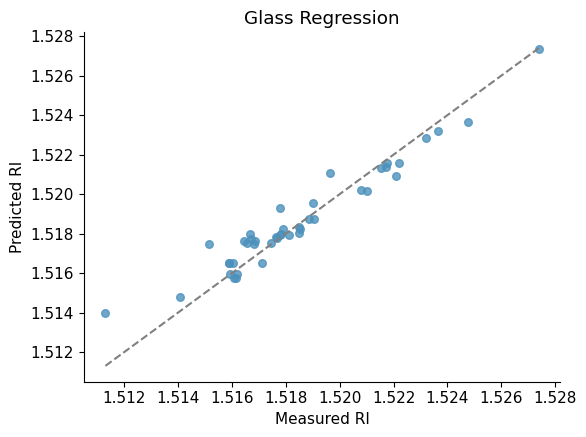

In [3]:
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score, root_mean_squared_error
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = 'neg_root_mean_squared_error'

ridge_search = GridSearchCV(
    make_pipeline(StandardScaler(), Ridge()),
    {'ridge__alpha': [0.001, 0.01, 0.1, 1, 10, 100]},
    cv=cv, scoring=scoring, n_jobs=1,
).fit(X_train, y_train)
ridge = ridge_search.best_estimator_
ridge_pred = ridge.predict(X_test)
ridge_rmse = root_mean_squared_error(y_test, ridge_pred)
print('Selected alpha:', ridge_search.best_params_['ridge__alpha'])
print(f'Test RMSE: {ridge_rmse:.6f}; R²: {r2_score(y_test, ridge_pred):.3f}')

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.scatter(y_test, ridge_pred, color=BLUE, s=30, alpha=0.8)
limits = [min(y_test.min(), ridge_pred.min()), max(y_test.max(), ridge_pred.max())]
ax.plot(limits, limits, '--', color='0.5')
ax.set(title='Glass Regression', xlabel='Measured RI', ylabel='Predicted RI')
ax.ticklabel_format(useOffset=False, style='plain')
fig.tight_layout()
plt.show()

## 2. Permutation Importance

Shuffle one feature, predict with the fitted model, and recompute test RMSE. Do not retrain.
Repeat $K=50$ times per feature:

$$I_j = \frac{1}{K}\sum_{k=1}^{K}(E_{k,j}-E_0).$$

$E_0$ is the original RMSE; $E_{k,j}$ is the RMSE after shuffling feature $j$.
The following three-row example shows which values change.

In [4]:
rows = X_test.iloc[:3]
display(pd.DataFrame({
    'Na': rows['Na'], 'Ca before': rows['Ca'],
    'Ca after': np.roll(rows['Ca'].to_numpy(), 1),
    'Measured RI': y_test.loc[rows.index],
}))

,Na,Ca before,Ca after,Measured RI
sample_id,,,,
205,14.95,8.71,9.85,1.51617
51,13.72,10.06,8.71,1.52320
128,13.78,9.85,10.06,1.52081


,RMSE increase,SD across shuffles
Ca,0.005797,0.000542
Mg,0.002429,0.000248
Ba,0.001429,0.000191
Na,0.000793,0.000138
Al,0.000056,0.000025
K,0.000051,0.000055
Si,0.000009,0.000011
Fe,-0.000009,0.000003


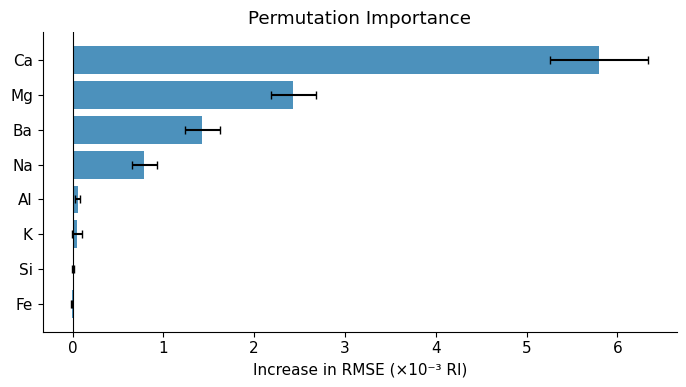

In [5]:
from sklearn.inspection import permutation_importance

ridge_perm = permutation_importance(
    ridge, X_test, y_test, scoring=scoring,
    n_repeats=50, random_state=23, n_jobs=1,
)
importance = pd.DataFrame({
    'RMSE increase': ridge_perm.importances_mean,
    'SD across shuffles': ridge_perm.importances_std,
}, index=features).sort_values('RMSE increase')
display(importance.iloc[::-1].round(6))

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(importance.index, importance['RMSE increase'] * 1000,
        xerr=importance['SD across shuffles'] * 1000,
        color=BLUE, capsize=3, error_kw={'ecolor': 'black'})
ax.axvline(0, color='black', linewidth=0.8)
ax.set(title='Permutation Importance', xlabel='Increase in RMSE (×10⁻³ RI)')
fig.tight_layout()
plt.show()

Ca gives the largest RMSE increase for this Ridge model.
Negative importance means the score improved after shuffling.
Whiskers show one standard deviation across shuffles, not a confidence interval.

## 3. Partial Dependence

Set Ca to the same value in every test row. Keep each row's other inputs and average the predictions:

$$\widehat{\mathrm{PD}}_j(z)=\frac{1}{n}\sum_{i=1}^{n}\widehat f(z,\mathbf{x}_{i,-j}).$$

$z$ is the assigned value; $n=43$. No measured target values are needed.

In [6]:
modified = X_test.assign(Ca=8.0)
pred_at_8 = ridge.predict(modified)
table = X_test[['Ca', 'Na', 'Mg']].iloc[:3].rename(columns={'Ca': 'Original Ca'})
table['Ca set to'] = 8.0
table['Predicted RI'] = pred_at_8[:3]
display(table.round(5))

pd_at_8 = pred_at_8.mean()
pd_at_10 = ridge.predict(X_test.assign(Ca=10.0)).mean()
print(f'PD(8): {pd_at_8:.5f}; PD(10): {pd_at_10:.5f}')
print(f'Difference: {pd_at_10 - pd_at_8:.5f}')

PD(8): 1.51600; PD(10): 1.52159
Difference: 0.00559


,Original Ca,Na,Mg,Ca set to,Predicted RI
sample_id,,,,,
205,8.71,14.95,0.00,8.0,1.51376
51,10.06,13.72,3.72,8.0,1.51708
128,9.85,13.78,2.28,8.0,1.51502


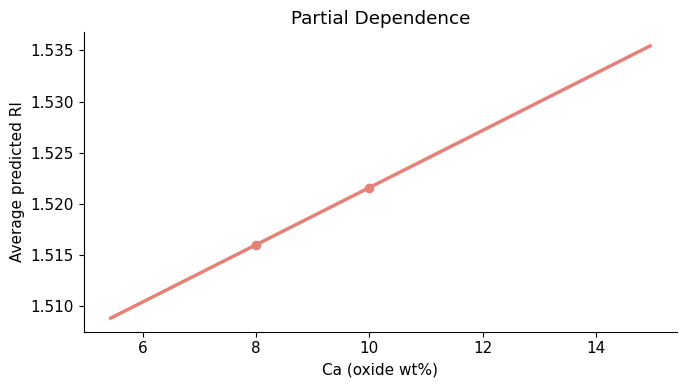

In [7]:
from sklearn.inspection import partial_dependence

ca_grid = np.linspace(X_test['Ca'].min(), X_test['Ca'].max(), 201)
ridge_pd = partial_dependence(
    ridge, X_test, features=['Ca'], method='brute', custom_values={'Ca': ca_grid},
)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(ca_grid, ridge_pd['average'][0], color=RED, linewidth=2.5)
ax.scatter([8, 10], [pd_at_8, pd_at_10], color=RED, zorder=3)
ax.set(title='Partial Dependence', xlabel='Ca (oxide wt%)',
       ylabel='Average predicted RI')
ax.ticklabel_format(axis='y', useOffset=False, style='plain')
fig.tight_layout()
plt.show()

The PDP is straight because Ridge is linear in these inputs.
The different predictions at Ca = 8 come from each sample's other seven inputs.

## 4. Nonlinear PDP and ICE

Fit a random forest using the same training split and cross-validation folds.
Each ICE curve follows one sample; the PDP is their pointwise average:

$$\mathrm{ICE}_{i,j}(z)=\widehat f(z,\mathbf{x}_{i,-j}),\qquad
\widehat{\mathrm{PD}}_j(z)=\frac{1}{n}\sum_i\mathrm{ICE}_{i,j}(z).$$

In [8]:
from sklearn.ensemble import RandomForestRegressor

forest_search = GridSearchCV(
    RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=1),
    {'max_depth': [None, 5, 10], 'min_samples_leaf': [1, 3, 5]},
    cv=cv, scoring=scoring, n_jobs=1,
).fit(X_train, y_train)
forest = forest_search.best_estimator_
forest_pred = forest.predict(X_test)
forest_rmse = root_mean_squared_error(y_test, forest_pred)
print('Forest parameters:', forest_search.best_params_)
display(pd.DataFrame({
    'Test RMSE': [ridge_rmse, forest_rmse],
    'Test R2': [r2_score(y_test, ridge_pred), r2_score(y_test, forest_pred)],
}, index=['Ridge', 'Random forest']).round(6))

Forest parameters: {'max_depth': 10, 'min_samples_leaf': 1}


,Test RMSE,Test R2
Ridge,0.000850,0.920100
Random forest,0.001329,0.804634


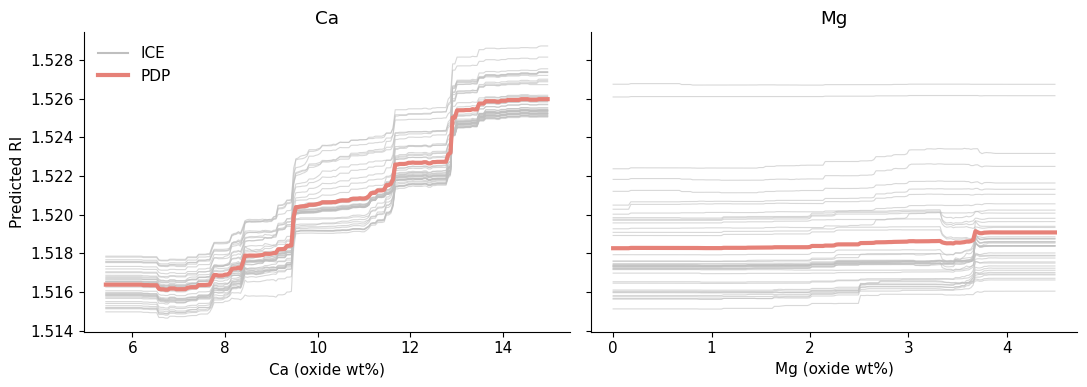

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, feature in zip(axes, ['Ca', 'Mg']):
    grid = np.linspace(X_test[feature].min(), X_test[feature].max(), 201)
    curves = partial_dependence(
        forest, X_test, features=[feature], method='brute', kind='both',
        custom_values={feature: grid},
    )
    ax.plot(grid, curves['individual'][0].T, color='0.75', linewidth=0.8, alpha=0.6)
    ax.plot([], [], color='0.75', label='ICE')
    ax.plot(grid, curves['average'][0], color=RED, linewidth=3, label='PDP')
    ax.set(title=feature, xlabel=f'{feature} (oxide wt%)')
    ax.ticklabel_format(axis='y', useOffset=False, style='plain')
axes[0].set_ylabel('Predicted RI')
axes[0].legend(frameon=False)
fig.tight_layout()
plt.show()

Ca gives a larger average response than Mg over these ranges. This does not rank predictive importance.
The gray curves show sample differences, not uncertainty intervals.
Ridge has the lower test RMSE here; nonlinearity does not guarantee better prediction.

PDP averages **predictions**, not input values. Compare the two calculations at Ca = 10:

In [10]:
mean_inputs = X_test.mean().to_frame().T.assign(Ca=10.0)
display(pd.Series({
    'Average of 43 predictions': forest.predict(X_test.assign(Ca=10.0)).mean(),
    'Prediction at mean other inputs': forest.predict(mean_inputs)[0],
}, name='Predicted RI').round(5))

Average of 43 predictions          1.52055
Prediction at mean other inputs    1.51972
Name: Predicted RI, dtype: float64

## 5. Shapley Values

A feature's marginal contribution depends on which features are already included.
SHAP averages these contributions over feature orders.
Use these illustrative two-feature predictions to compare both orders.

In [11]:
v_none, v_ca, v_si, v_both = 1.500, 1.510, 1.504, 1.520
orders = pd.DataFrame({
    'Ca': [v_ca - v_none, v_both - v_si],
    'Si': [v_both - v_ca, v_si - v_none],
}, index=['Ca then Si', 'Si then Ca'])
display(orders.round(3))
display(orders.mean().rename('SHAP value').round(3))
print(f'{v_none:.3f} + {orders["Ca"].mean():.3f} + {orders["Si"].mean():.3f} = {v_both:.3f}')

1.500 + 0.013 + 0.007 = 1.520


,Ca,Si
Ca then Si,0.010,0.010
Si then Ca,0.016,0.004


Ca    0.013
Si    0.007
Name: SHAP value, dtype: float64

## 6. Local SHAP

For the fitted forest, use all 171 training rows as the background.
Fix included features to the sample's values, fill omitted features from each background row, and average predictions.
With eight inputs, exact enumeration is feasible.

$$\widehat f(\mathbf{x})=\phi_0+\sum_{j=1}^{8}\phi_j(\mathbf{x}).$$

$\phi_0$ is the mean background prediction; $\phi_j$ is feature $j$'s assigned contribution.

In [12]:
import shap

def predict_glass(values):
    return forest.predict(pd.DataFrame(values, columns=features))


background = shap.maskers.Independent(X_train, max_samples=len(X_train))
explainer = shap.ExactExplainer(predict_glass, background, feature_names=features)
explanations = explainer(X_test, silent=True)
phi = explanations.values
baseline = float(explanations.base_values[0])
np.testing.assert_allclose(
    explanations.base_values + phi.sum(axis=1), forest_pred, rtol=0, atol=1e-10,
)
sample_id = 51
position = X_test.index.get_loc(sample_id)
local_phi = phi[position]
prediction = forest_pred[position]
print(f'Sample {sample_id}: {baseline:.5f} + {local_phi.sum():.5f} = {prediction:.5f}')

Sample 51: 1.51833 + 0.00508 = 1.52341


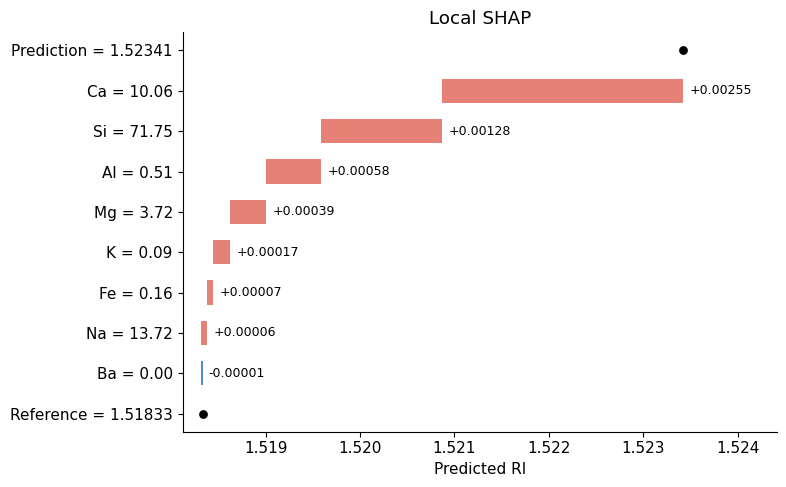

In [13]:
order = np.argsort(np.abs(local_phi))
steps = np.r_[baseline, baseline + np.cumsum(local_phi[order])]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(range(1, 9), np.abs(local_phi[order]),
        left=np.minimum(steps[:-1], steps[1:]), height=0.6,
        color=np.where(local_phi[order] >= 0, RED, BLUE))
ax.scatter([baseline, prediction], [0, 9], color='black', s=28)
labels = [f'Reference = {baseline:.5f}'] + [
    f'{features[j]} = {X_test.iloc[position, j]:.2f}' for j in order
] + [f'Prediction = {prediction:.5f}']
ax.set_yticks(range(10), labels)
for k, j in enumerate(order, 1):
    ax.text(steps[k] + 0.00007, k, f'{local_phi[j]:+.5f}', va='center', fontsize=9)
ax.set_xlim(steps.min() - 0.0002, steps.max() + 0.001)
ax.set(title='Local SHAP', xlabel='Predicted RI')
ax.ticklabel_format(axis='x', useOffset=False, style='plain')
fig.tight_layout()
plt.show()

Red contributions raise the prediction relative to the reference; blue contributions lower it.
Ca and Si give the largest positive contributions for sample 51.
The display order is not the feature-order averaging used in the calculation.

## 7. Global SHAP

Average absolute contributions over the 43 test samples:

$$I_j^{\mathrm{SHAP}}=\frac{1}{n}\sum_{i=1}^{n}|\phi_j(\mathbf{x}_i)|.$$

This summarizes magnitude. The beeswarm keeps signed contributions; color shows the observed feature value.

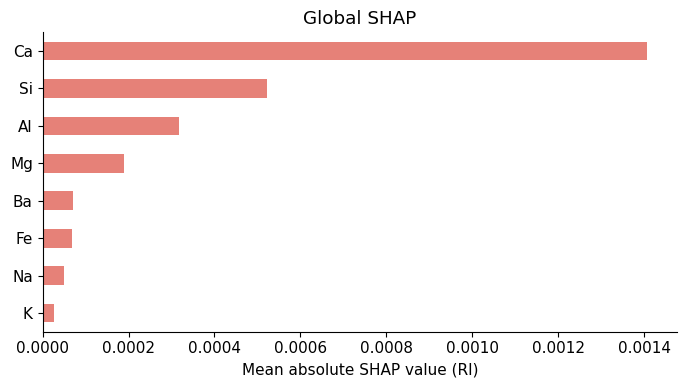

In [14]:
mean_shap = pd.Series(np.abs(phi).mean(axis=0), index=features)
fig, ax = plt.subplots(figsize=(7, 4))
mean_shap.sort_values().plot.barh(ax=ax, color=RED)
ax.set(title='Global SHAP', xlabel='Mean absolute SHAP value (RI)')
ax.ticklabel_format(axis='x', useOffset=False, style='plain')
fig.tight_layout()
plt.show()

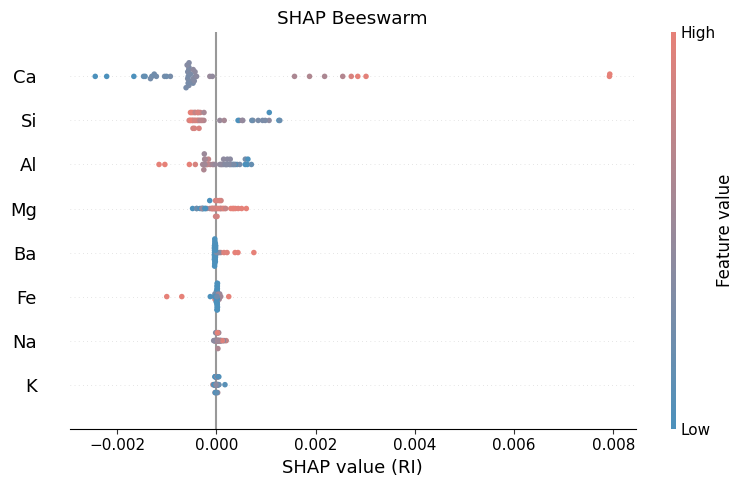

In [15]:
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.text import Text

cmap = LinearSegmentedColormap.from_list('feature_values', [BLUE, RED])
np.random.seed(SEED)
ax = shap.plots.beeswarm(explanations, max_display=8, color=cmap,
                         show=False, plot_size=(8, 5))
ax.set(title='SHAP Beeswarm', xlabel='SHAP value (RI)')
ax.ticklabel_format(axis='x', useOffset=False, style='plain')
for text in ax.figure.findobj(match=Text):
    text.set_color('black')
plt.tight_layout()
plt.show()

## 8. Feature Importance Comparison

Compare these measures for the **same forest**. Their numerical scales differ.

| Measure | Meaning |
|---|---|
| Impurity importance | Reduction in training split impurity |
| Test permutation importance | Increase in test RMSE after shuffling |
| Mean absolute SHAP | Magnitude of assigned prediction contributions |

In [16]:
forest_perm = permutation_importance(
    forest, X_test, y_test, scoring=scoring,
    n_repeats=50, random_state=23, n_jobs=1,
)
comparison = pd.DataFrame({
    'Impurity importance': forest.feature_importances_,
    'Test RMSE increase': forest_perm.importances_mean,
    'Mean absolute SHAP': mean_shap,
}, index=features)
display(comparison.sort_values('Mean absolute SHAP', ascending=False).round(6))

,Impurity importance,Test RMSE increase,Mean absolute SHAP
Ca,0.691823,0.002128,0.001406
Si,0.127720,0.000365,0.000523
Al,0.064880,0.000255,0.000318
Mg,0.040400,0.000031,0.000189
Ba,0.010976,0.000010,0.000071
Fe,0.025529,-0.000028,0.000070
Na,0.022156,0.000019,0.000050
K,0.016517,-0.000004,0.000027


Impurity importance can favor features with many split points. SHAP describes prediction contributions, not improvements in accuracy.
Correlated features can substitute for each other, reducing individual permutation importance.

Glass compositions are dependent. Hypothetical mixtures may be unrealistic, and SHAP allocations depend on the background and masking rule.
These explanations describe model behavior; they do not establish physical causes.